# 2025-03-03: Data Distribution of CHILDES

## Prelude

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from verb_overgen.prep.common import Parse

In [3]:
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt
from os import environ

In [4]:
dataset = pl.read_parquet(f"{environ['DATA_PATH_BASE']}/babylm/aochildes_parsed.parquet")

## Data Quantity

We use AOCHILDES within version 1 of BabyLM, the count of each split is as follows:

In [5]:
dataset.select(
    pl.col("split").value_counts().struct.unnest()
)

split,count
enum,u32
"""test""",60000
"""dev""",70000
"""train""",80000


Some 19% sentences are too short to be a full sentence (2 words, punctuation included), therefore we don't parse them to save time.

In [6]:
print("{:.3%}".format(
    dataset.select(pl.col("parse").null_count()).item() / dataset.height
))

18.536%


The number of words in each sentence is a long-tail distribution.

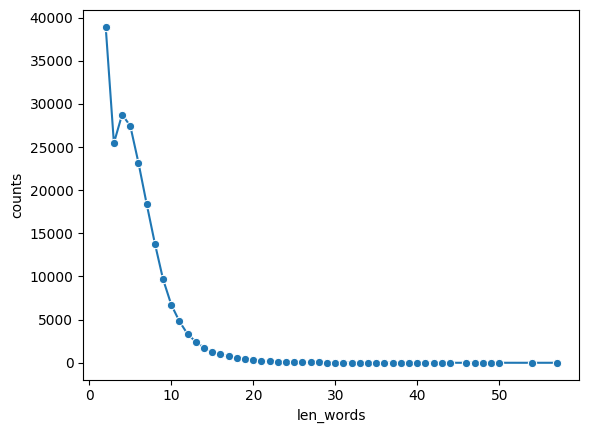

In [7]:
df_len_words = dataset.select(
    pl.when(pl.col("parse").is_not_null())
      .then(pl.col("parse").struct.field("word").list.len())
      .otherwise(pl.lit(2))
      .value_counts()
      .struct.rename_fields(["len_words", "counts"])
      .struct.unnest()
)

ax = sns.lineplot(data=df_len_words, x="len_words", y="counts", marker="o")

## Parse

We extract subject-verb-object structures from the parsed sentences.

In [8]:
from functools import partial
from verb_overgen.prep.lib.pattern_matching import match_svo
from verb_overgen.prep.lib.lexical import to_lemma

dataset_trans_verb = dataset.filter(
    pl.col("parse").is_not_null(),
    pl.col("parse").struct.field("rel").pipe(lambda r: r.list.contains("nsubj") & r.list.contains("dobj"))
).with_columns(
    trans_verb_index := pl.col("parse").pipe(match_svo).alias("trans_verb_index"),
    trans_verb := pl.col("parse").struct.field("word").list.gather(trans_verb_index - 1).alias("trans_verb"),
    trans_verb_lemma := trans_verb.list.eval(pl.element().map_elements(partial(to_lemma, pos="v"), return_dtype=pl.String)).alias("trans_verb_lemma")
)

The default BiLSTM parser still makes mistakes. I should probably run the faster RoBERTa version? (Now fixing some pickle errors, urgh)

Take the word "talk" as an example, which is clearly not a transitive verb. Dangling prepositions can break the parser.

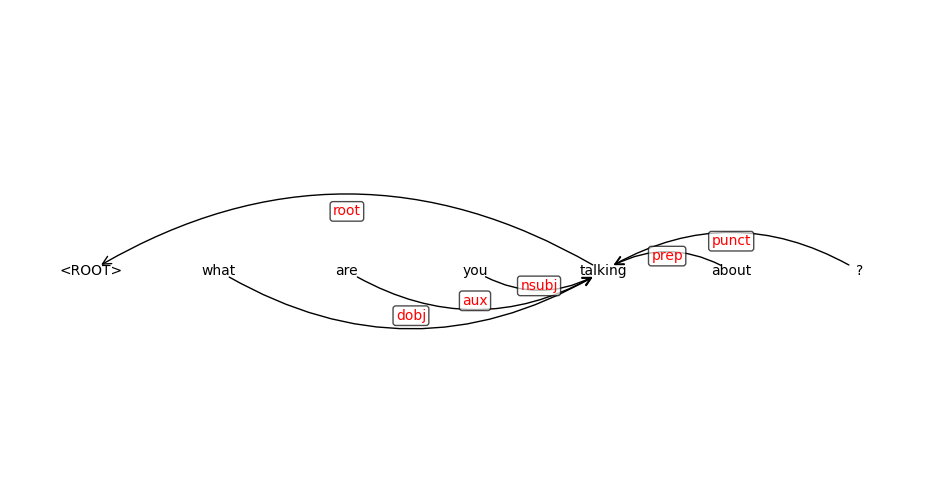

In [17]:
from verb_overgen.prep.lib.graph import create_parse_graph, draw_parse_graph

dataset_transitive_talk = dataset_trans_verb.filter(
    pl.col("trans_verb_lemma").list.contains("talk")
)

draw_parse_graph(create_parse_graph(dataset_transitive_talk[2, "parse"])).show()

Some childish speech can be difficult to parse. For example this sentence is parsed as "parrots talk hens"

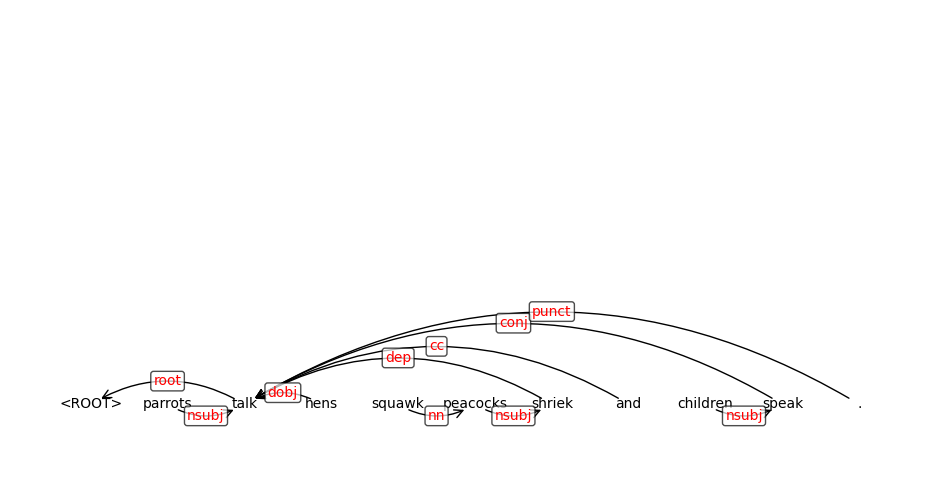

In [10]:
draw_parse_graph(create_parse_graph(dataset_transitive_talk[4, "parse"])).show()

# Bidgood (2021) Verbs

We now pull over Bidgood's (2021) verb sheet and check the distribution of verb categories in the parsed sentences.

In [11]:
from verb_overgen.prep.lib.lexical import BIDGOOD_VERBS

df_bidgood_v = pl.DataFrame([(category, word) for category, s in BIDGOOD_VERBS.items() for word in s], orient="row", schema=pl.Schema({
    "category": pl.Enum(BIDGOOD_VERBS.keys()),
    "word": pl.String
}))

In [12]:
df_trans_verb_count = dataset_trans_verb.select(
    pl.col("trans_verb_lemma").list.explode().value_counts().struct.rename_fields(["word", "count"]).struct.unnest()
)

df_bidgood_v_count = df_bidgood_v.join(df_trans_verb_count, on="word", how="left", maintain_order="left").with_columns(
    pl.col("count").fill_null(0)
)

In [13]:
df_bidgood_v_count.group_by("category").agg(pl.sum("count"))

category,count
enum,u32
"""transitive_only""",4296
"""alternating""",1686
"""intransitive_only""",2168


Let's check how these intransitive only verbs have 2168 transitive occurrences.

In [14]:
with pl.Config(set_tbl_rows=-1):
    display(df_bidgood_v_count.filter(pl.col("category") == "intransitive_only").sort("count", descending=True))

category,word,count
enum,str,u32
"""intransitive_only""","""eat""",918
"""intransitive_only""","""go""",679
"""intransitive_only""","""drink""",141
"""intransitive_only""","""sing""",138
"""intransitive_only""","""come""",72
"""intransitive_only""","""talk""",49
"""intransitive_only""","""run""",33
"""intransitive_only""","""climb""",26
"""intransitive_only""","""jump""",21


In [19]:
dataset.filter(
    pl.col("text").str.contains("live")
)

index,text,split,parse
u32,str,enum,struct[3]
10841,"""i would love to get on a sched…","""train""","{[""nsubj"", ""aux"", … ""punct""],[3, 3, … 3],[""i"", ""would"", … ""?""]}"
14153,"""oliver ?""","""train""",null
14477,"""porcupines live in forests por…","""train""","{[""nsubj"", ""root"", … ""punct""],[2, 0, … 2],[""porcupines"", ""live"", … ""?""]}"
14481,"""walrus they live in the ocean …","""train""","{[""dep"", ""nsubj"", … ""punct""],[3, 3, … 3],[""walrus"", ""they"", … ""?""]}"
14780,"""but koalas do live in trees ?""","""train""","{[""cc"", ""nsubj"", … ""punct""],[4, 4, … 4],[""but"", ""koalas"", … ""?""]}"
…,…,…,…
204312,"""i went to all the trouble of m…","""test""","{[""nsubj"", ""root"", … ""punct""],[2, 0, … 2],[""i"", ""went"", … "".""]}"
206340,"""if the person probably can't h…","""test""","{[""mark"", ""det"", … ""punct""],[6, 3, … 6],[""if"", ""the"", … ""?""]}"
207109,"""do you live with me ?""","""test""","{[""aux"", ""nsubj"", … ""punct""],[3, 3, … 3],[""do"", ""you"", … ""?""]}"


Let's first check the example "laugh":

In [15]:
from ipywidgets import Dropdown, interact

In [16]:
def show_all_cases_for_example(example):
    df = dataset_trans_verb.filter(
        pl.col("trans_verb_lemma").list.contains(example)
    )

    if df.height >= 10:
        df = df.head(10)

    for row in range(df.height):
        fig = draw_parse_graph(create_parse_graph(df[row, "parse"]))
        fig.suptitle("#{row}: {text}".format(
            row=df[row, "index"],
            text=df[row, "text"],
        ))
        fig.show()

interact(show_all_cases_for_example, example=Dropdown(options=df_bidgood_v_count.filter(pl.col("category")=="intransitive_only")["word"].unique().to_list(), value="laugh"))

interactive(children=(Dropdown(description='example', index=24, options=('chortle', 'climb', 'go', 'groan', 't…

<function __main__.show_all_cases_for_example(example)>